# Core vs RoA/CRR

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
from matplotlib.lines import Line2D

plt.rcParams["figure.dpi"] = 300

In [2]:
def legend_crr_roa():

    legend_elements = [
        Line2D([0],[0], color="C0", linestyle="--", lw=3, label="CRR 90th"),
        Line2D([0],[0], color="C1", linestyle="--", lw=3, label="CRR 95th"),
        Line2D([0],[0], color="C2", linestyle="--", lw=3, label="CRR 98th"),

        Line2D([0],[0], color="C0", linestyle="-", lw=3, label="RoA 90th"),
        Line2D([0],[0], color="C1", linestyle="-", lw=3, label="RoA 95th"),
        Line2D([0],[0], color="C2", linestyle="-", lw=3, label="RoA 98th"),
    ]

    plt.legend(
        handles=legend_elements,
        fontsize=14,
        ncol=2
    )

# Load parquet

In [3]:
base = "/gws/ssde/j25b/swift/mendrika/asnie/database/parquet"

# thresholds
core_thresholds = [79.53, 80.744, 82.64]
crr_thresholds  = [1.746, 2.578, 4.365]
roa_thresholds  = [1.636, 2.921, 4.886]

cores = {}
crrs = {}
roas = {}

# load cores
for thr in core_thresholds:
    
    tag = f"thr_{thr}".replace(".", "p")
    
    cores[thr] = pd.read_parquet(
        f"{base}/core_2024_{tag}.parquet"
    )

# load CRR
for thr in crr_thresholds:
    
    tag = f"thr_{thr}".replace(".", "p")
    
    crrs[thr] = pd.read_parquet(
        f"{base}/crr_2024_{tag}.parquet"
    )

# load RoA
for thr in roa_thresholds:
    
    tag = f"thr_{thr}".replace(".", "p")
    
    roas[thr] = pd.read_parquet(
        f"{base}/roa_2024_{tag}.parquet"
    )

In [4]:
for thr in core_thresholds:
    print("core", thr, cores[thr]["time"].min(), cores[thr]["time"].max())

for thr in roa_thresholds:
    print("roa", thr, roas[thr]["time"].min(), roas[thr]["time"].max())

for thr in crr_thresholds:
    print("crr", thr, crrs[thr]["time"].min(), crrs[thr]["time"].max())

core 79.53 2024-06-01 00:00:00 2024-09-30 20:15:00
core 80.744 2024-06-01 00:00:00 2024-09-30 20:15:00
core 82.64 2024-06-01 16:30:00 2024-09-30 18:15:00
roa 1.636 2024-06-01 00:00:00 2024-09-30 23:45:00
roa 2.921 2024-06-01 00:00:00 2024-09-30 23:45:00
roa 4.886 2024-06-01 00:00:00 2024-09-30 23:45:00
crr 1.746 2024-06-01 00:00:00 2024-08-05 14:00:00
crr 2.578 2024-06-01 00:00:00 2024-08-05 14:00:00
crr 4.365 2024-06-01 00:00:00 2024-08-05 14:00:00


In [5]:
common_times = set(cores[79.53]["time"]).intersection(roas[1.636]["time"])
print("Core–RoA timesteps:", len(common_times))

common_times = set(cores[79.53]["time"]).intersection(crrs[1.746]["time"])
print("Core–CRR timesteps:", len(common_times))

Core–RoA timesteps: 4875
Core–CRR timesteps: 1383


# Compute distance

In [6]:
def latlon_to_xy_km(lat, lon):
    """
    Convert latitude and longitude coordinates to approximate Cartesian
    coordinates in kilometres.

    This function applies a simple equirectangular projection to transform
    geographic coordinates (lat, lon) into planar (x, y) coordinates. The
    conversion is suitable for computing Euclidean distances between nearby
    points (e.g., storm-object centroids) over a limited geographic region.

    Longitude distances are scaled by cos(mean latitude) to account for the
    decrease in east–west distance away from the equator.

    Parameters
    ----------
    lat : array-like
        Latitudes in degrees.
    lon : array-like
        Longitudes in degrees.

    Returns
    -------
    xy : ndarray of shape (N, 2)
        Array containing projected coordinates in kilometres, where each row
        corresponds to a point (x, y).
    """

    R = 6371.0

    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)

    x = R * lon_rad * np.cos(np.mean(lat_rad))                      # mean to make sure it's consistent across dataset (assuming a single reference latitude for simplicity)
    y = R * lat_rad

    return np.column_stack((x, y))

In [7]:
def core_to_rain_distances(df_core, df_rain, start_hour=12, end_hour=21):

    matches = []

    # Restrict to convectively active period
    core_active = df_core[
        (df_core["hour"] >= start_hour) &
        (df_core["hour"] <= end_hour)
    ]

    rain_active = df_rain[
        (df_rain["hour"] >= start_hour) &
        (df_rain["hour"] <= end_hour)
    ]

    # Group rainfall once
    rain_groups = {t: g for t, g in rain_active.groupby("time")}

    for t, core_group in core_active.groupby("time"):

        rain_group = rain_groups.get(t)

        if rain_group is None or len(core_group) == 0:
            continue

        rain_xy = latlon_to_xy_km(
            rain_group["lat_centroid"].values,
            rain_group["lon_centroid"].values
        )

        tree = cKDTree(rain_xy)

        core_xy = latlon_to_xy_km(
            core_group["lat_centroid"].values,
            core_group["lon_centroid"].values
        )

        distances, _ = tree.query(core_xy, k=1)

        matches.extend(distances)

    return np.array(matches)

In [8]:
distances_crr = {}
distances_roa = {}

# Core → CRR
for cthr, rthr in zip(core_thresholds, crr_thresholds):

    core_df = cores[cthr]
    rain_df = crrs[rthr]

    common_times = set(core_df["time"]).intersection(rain_df["time"])

    core_df = core_df[core_df["time"].isin(common_times)]
    rain_df = rain_df[rain_df["time"].isin(common_times)]

    distances_crr[rthr] = core_to_rain_distances(core_df, rain_df)

    print(
        f"core {cthr} vs crr {rthr}:",
        len(distances_crr[rthr]),
        "matches"
    )


# Core → RoA
for cthr, rthr in zip(core_thresholds, roa_thresholds):

    core_df = cores[cthr]
    rain_df = roas[rthr]

    common_times = set(core_df["time"]).intersection(rain_df["time"])

    core_df = core_df[core_df["time"].isin(common_times)]
    rain_df = rain_df[rain_df["time"].isin(common_times)]

    distances_roa[rthr] = core_to_rain_distances(core_df, rain_df)

    print(
        f"core {cthr} vs roa {rthr}:",
        len(distances_roa[rthr]),
        "matches"
    )

core 79.53 vs crr 1.746: 2461 matches
core 80.744 vs crr 2.578: 1988 matches
core 82.64 vs crr 4.365: 627 matches
core 79.53 vs roa 1.636: 8569 matches
core 80.744 vs roa 2.921: 7413 matches
core 82.64 vs roa 4.886: 3397 matches


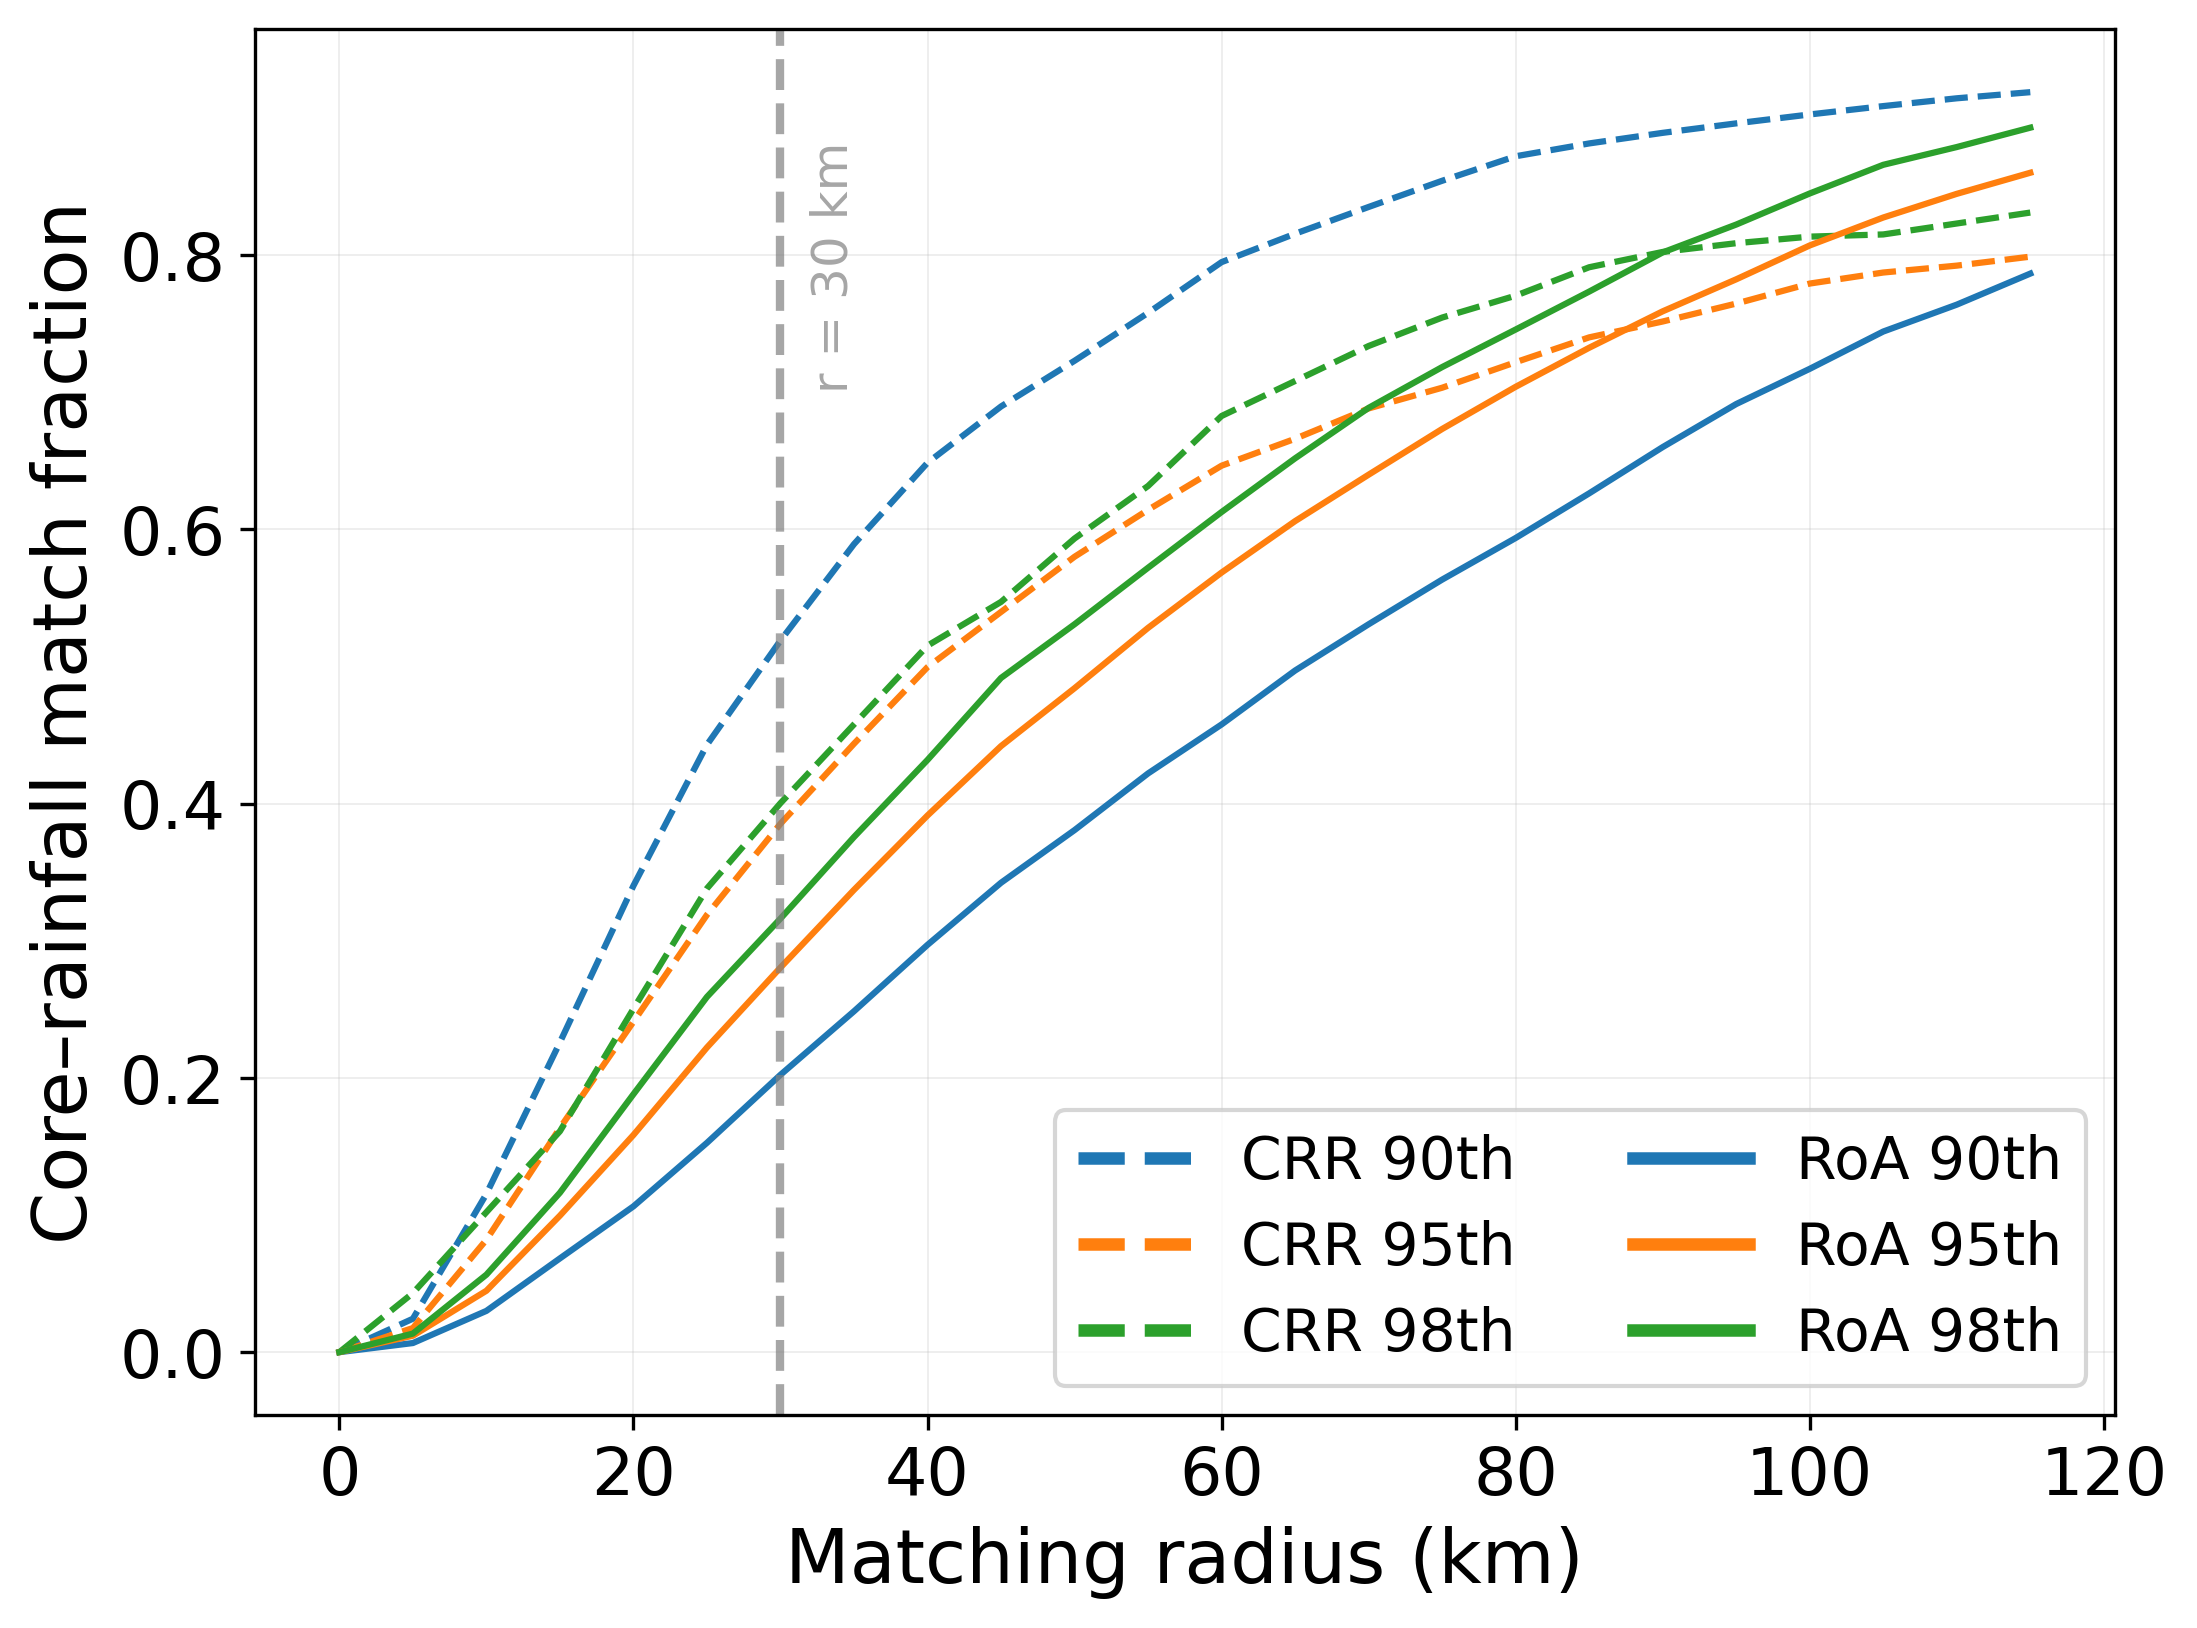

In [9]:
radii = np.arange(0, 120, 5)

plt.figure(figsize=(8,6), dpi=300)

colors = {
    "90": "tab:blue",
    "95": "tab:orange",
    "98": "tab:green"
}

# CRR (dashed)
for thr, d in distances_crr.items():

    if thr == 1.746:
        label = "CRR 90th"
        c = colors["90"]
    elif thr == 2.578:
        label = "CRR 95th"
        c = colors["95"]
    else:
        label = "CRR 98th"
        c = colors["98"]

    rates = [np.mean(d <= r) for r in radii]

    plt.plot(
        radii,
        rates,
        linestyle="--",
        color=c,
        label=label
    )

# RoA (solid)
for thr, d in distances_roa.items():

    if thr == 1.636:
        label = "RoA 90th"
        c = colors["90"]
    elif thr == 2.921:
        label = "RoA 95th"
        c = colors["95"]
    else:
        label = "RoA 98th"
        c = colors["98"]

    rates = [np.mean(d <= r) for r in radii]

    plt.plot(
        radii,
        rates,
        color=c,
        label=label
    )

plt.axvline(
    30,
    color="grey",
    linestyle="--",
    linewidth=2,
    alpha=0.7
)

plt.text(
    32,
    0.7,
    "r = 30 km",
    fontsize=12,
    color="grey",
    rotation=90,
    va="bottom",
    alpha=0.7
)

plt.xlabel("Matching radius (km)", fontsize=18)
plt.ylabel("Core–rainfall match fraction", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

legend_crr_roa()

plt.grid(True, linewidth=0.1)

plt.show()

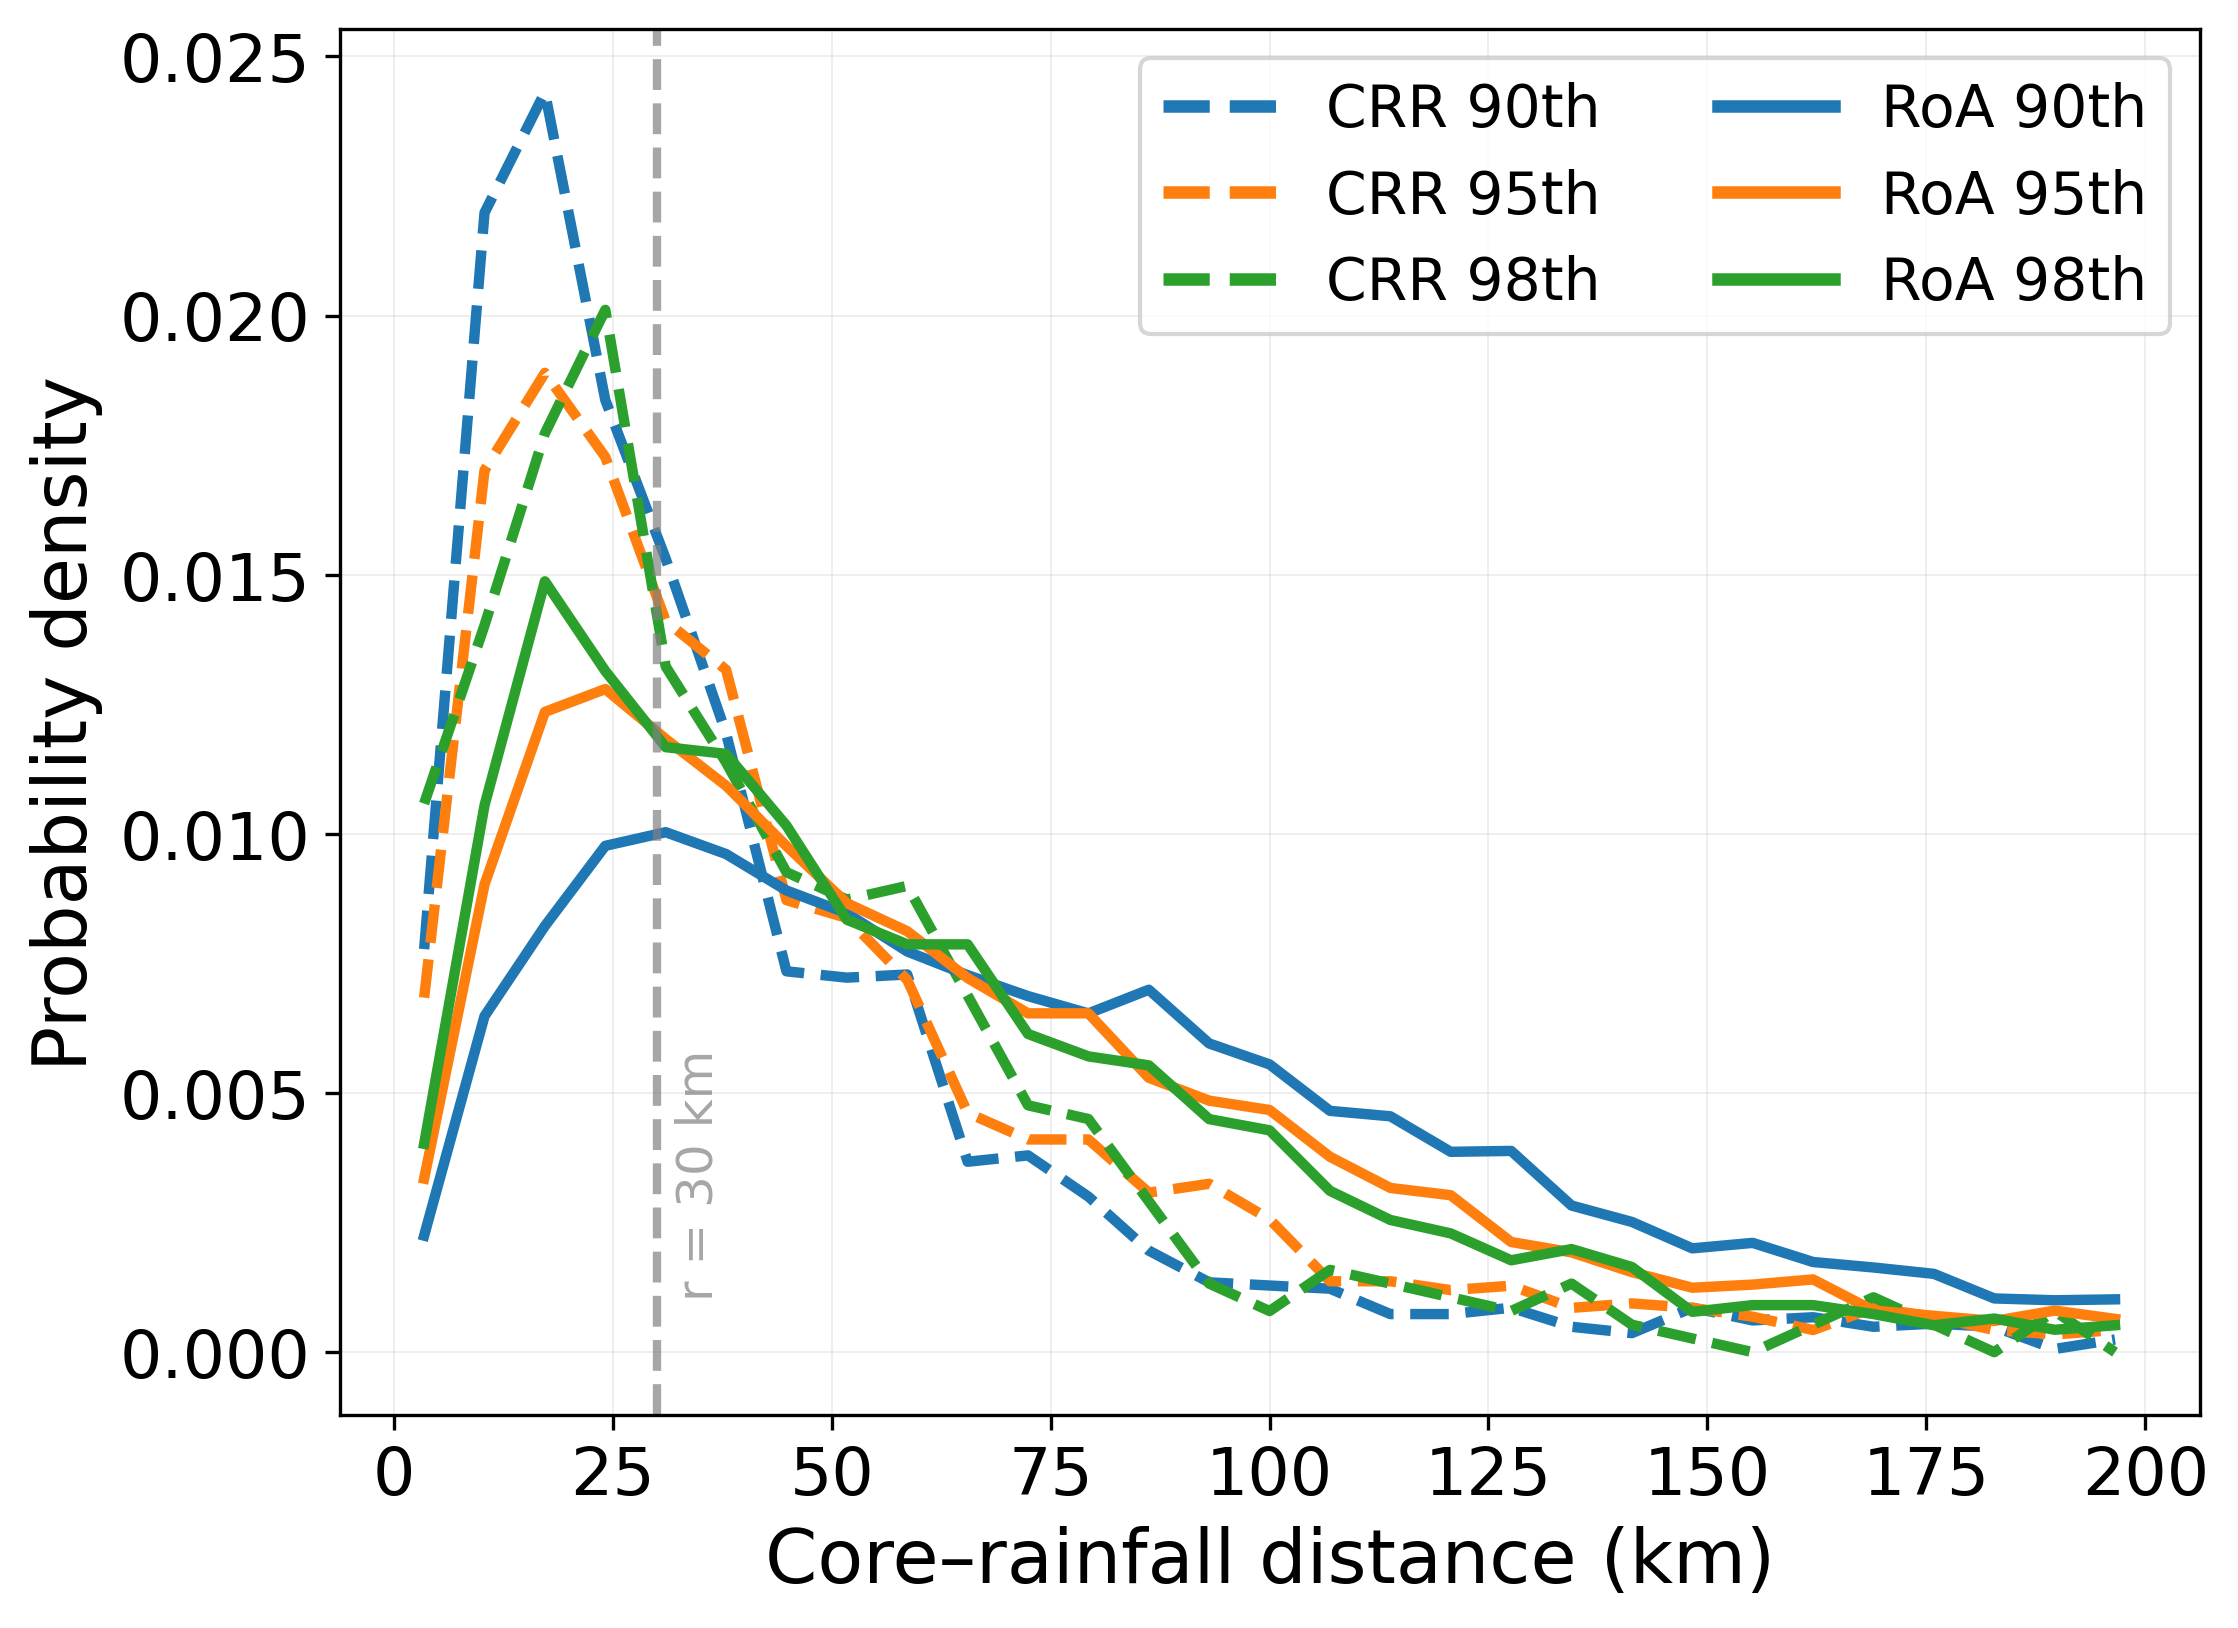

In [10]:
max_plot_radius = 200
bins = np.linspace(0, max_plot_radius, 30)

plt.figure(figsize=(8,6), dpi=300)

colors = {
    "90": "tab:blue",
    "95": "tab:orange",
    "98": "tab:green"
}

for thr, d in distances_crr.items():

    if thr == 1.746:
        label = "CRR 90th"
        c = colors["90"]
    elif thr == 2.578:
        label = "CRR 95th"
        c = colors["95"]
    else:
        label = "CRR 98th"
        c = colors["98"]

    dist = d[d <= max_plot_radius]

    hist, bin_edges = np.histogram(dist, bins=bins, density=True)
    bin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    plt.plot(
        bin_centres,
        hist,
        linestyle="--",
        color=c,
        linewidth=2.5,
        label=label
    )


for thr, d in distances_roa.items():

    if thr == 1.636:
        label = "RoA 90th"
        c = colors["90"]
    elif thr == 2.921:
        label = "RoA 95th"
        c = colors["95"]
    else:
        label = "RoA 98th"
        c = colors["98"]

    dist = d[d <= max_plot_radius]

    hist, bin_edges = np.histogram(dist, bins=bins, density=True)
    bin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    plt.plot(
        bin_centres,
        hist,
        color=c,
        linewidth=2.5,
        label=label
    )


plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Core–rainfall distance (km)", fontsize=18)
plt.ylabel("Probability density", fontsize=18)

plt.text(
    32,
    0.001,
    "r = 30 km",
    fontsize=12,
    color="grey",
    rotation=90,
    va="bottom",
    alpha=0.7
)

plt.axvline(
    30,
    color="grey",
    linestyle="--",
    linewidth=2,
    alpha=0.7
)

legend_crr_roa()

plt.grid(True, linewidth=0.1)

plt.show()

- RoA effective resolution

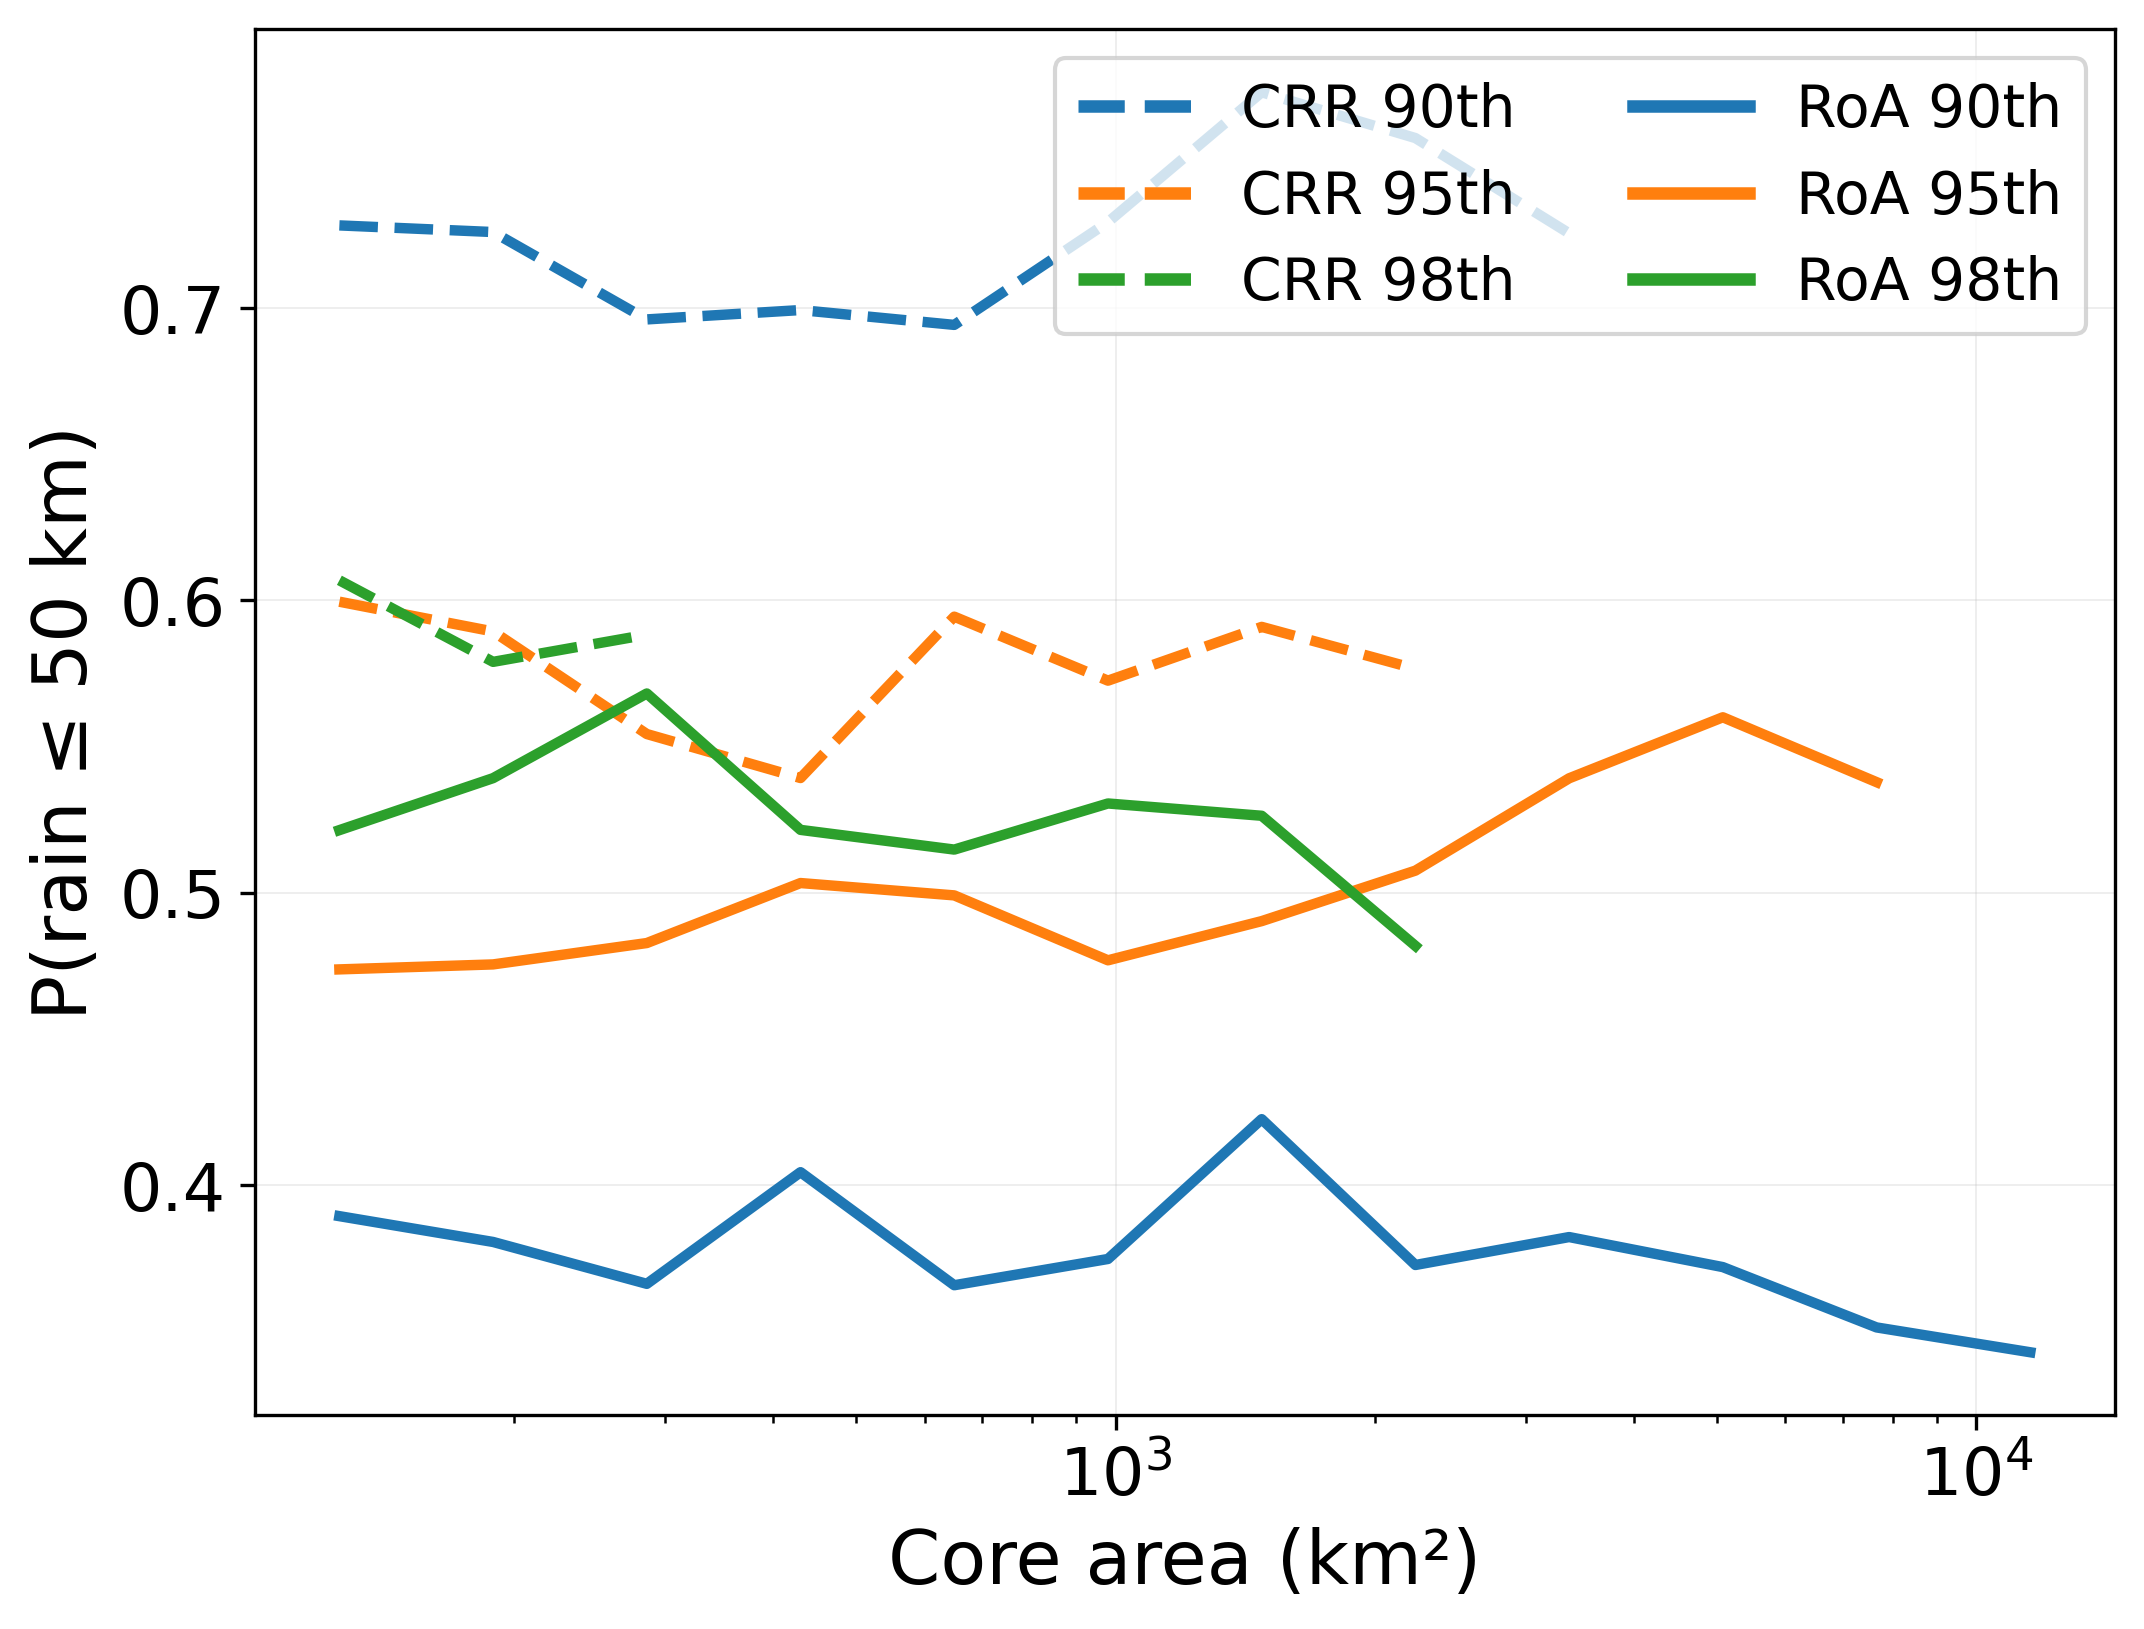

In [11]:
pairs = [
    (79.53, 1.746, "CRR 90th"),
    (80.744, 2.578, "CRR 95th"),
    (82.64, 4.365, "CRR 98th"),
    (79.53, 1.636, "RoA 90th"),
    (80.744, 2.921, "RoA 95th"),
    (82.64, 4.886, "RoA 98th"),
]

bins = np.logspace(2, 4.5, 15)

results = {}

for core_thr, rain_thr, label in pairs:

    df_core = cores[core_thr]

    if "CRR" in label:
        dist = distances_crr[rain_thr]
    else:
        dist = distances_roa[rain_thr]

    df_temp = df_core.iloc[:len(dist)].copy()
    df_temp["dist"] = dist

    df_temp["size_bin"] = pd.cut(df_temp["size"], bins)

    prob = (
        df_temp
        .groupby("size_bin", observed=True)["dist"]
        .apply(lambda x: np.mean(x <= 50))
    )

    counts = (
        df_temp
        .groupby("size_bin", observed=True)["dist"]
        .count()
    )

    valid_bins = counts[counts >= 100].index

    prob_clean = prob[valid_bins]

    bin_centres = [b.mid for b in prob_clean.index]

    results[label] = (bin_centres, prob_clean.values)

plt.figure(figsize=(8, 6), dpi=300)

for label, (x, y) in results.items():

    if "CRR" in label:
        linestyle = "--"
    else:
        linestyle = "-"

    if "90" in label:
        color = "C0"
    elif "95" in label:
        color = "C1"
    else:
        color = "C2"

    plt.plot(
        x,
        y,
        linestyle=linestyle,
        color=color,
        linewidth=2.5,
        label=label
    )

plt.xscale("log")

plt.xlabel("Core area (km²)", fontsize=18)
plt.ylabel("P(rain ≤ 50 km)", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

legend_crr_roa()

plt.grid(True, linewidth=0.1)

plt.show()

To focus on convective precipitation, the analysis was restricted to convectively active hours (12–21 UTC) and high rainfall percentiles (90th–98th). Although RoA represents total rainfall, these filters preferentially select intense convective rainfall events, making the comparison with convective cores more meaningful.

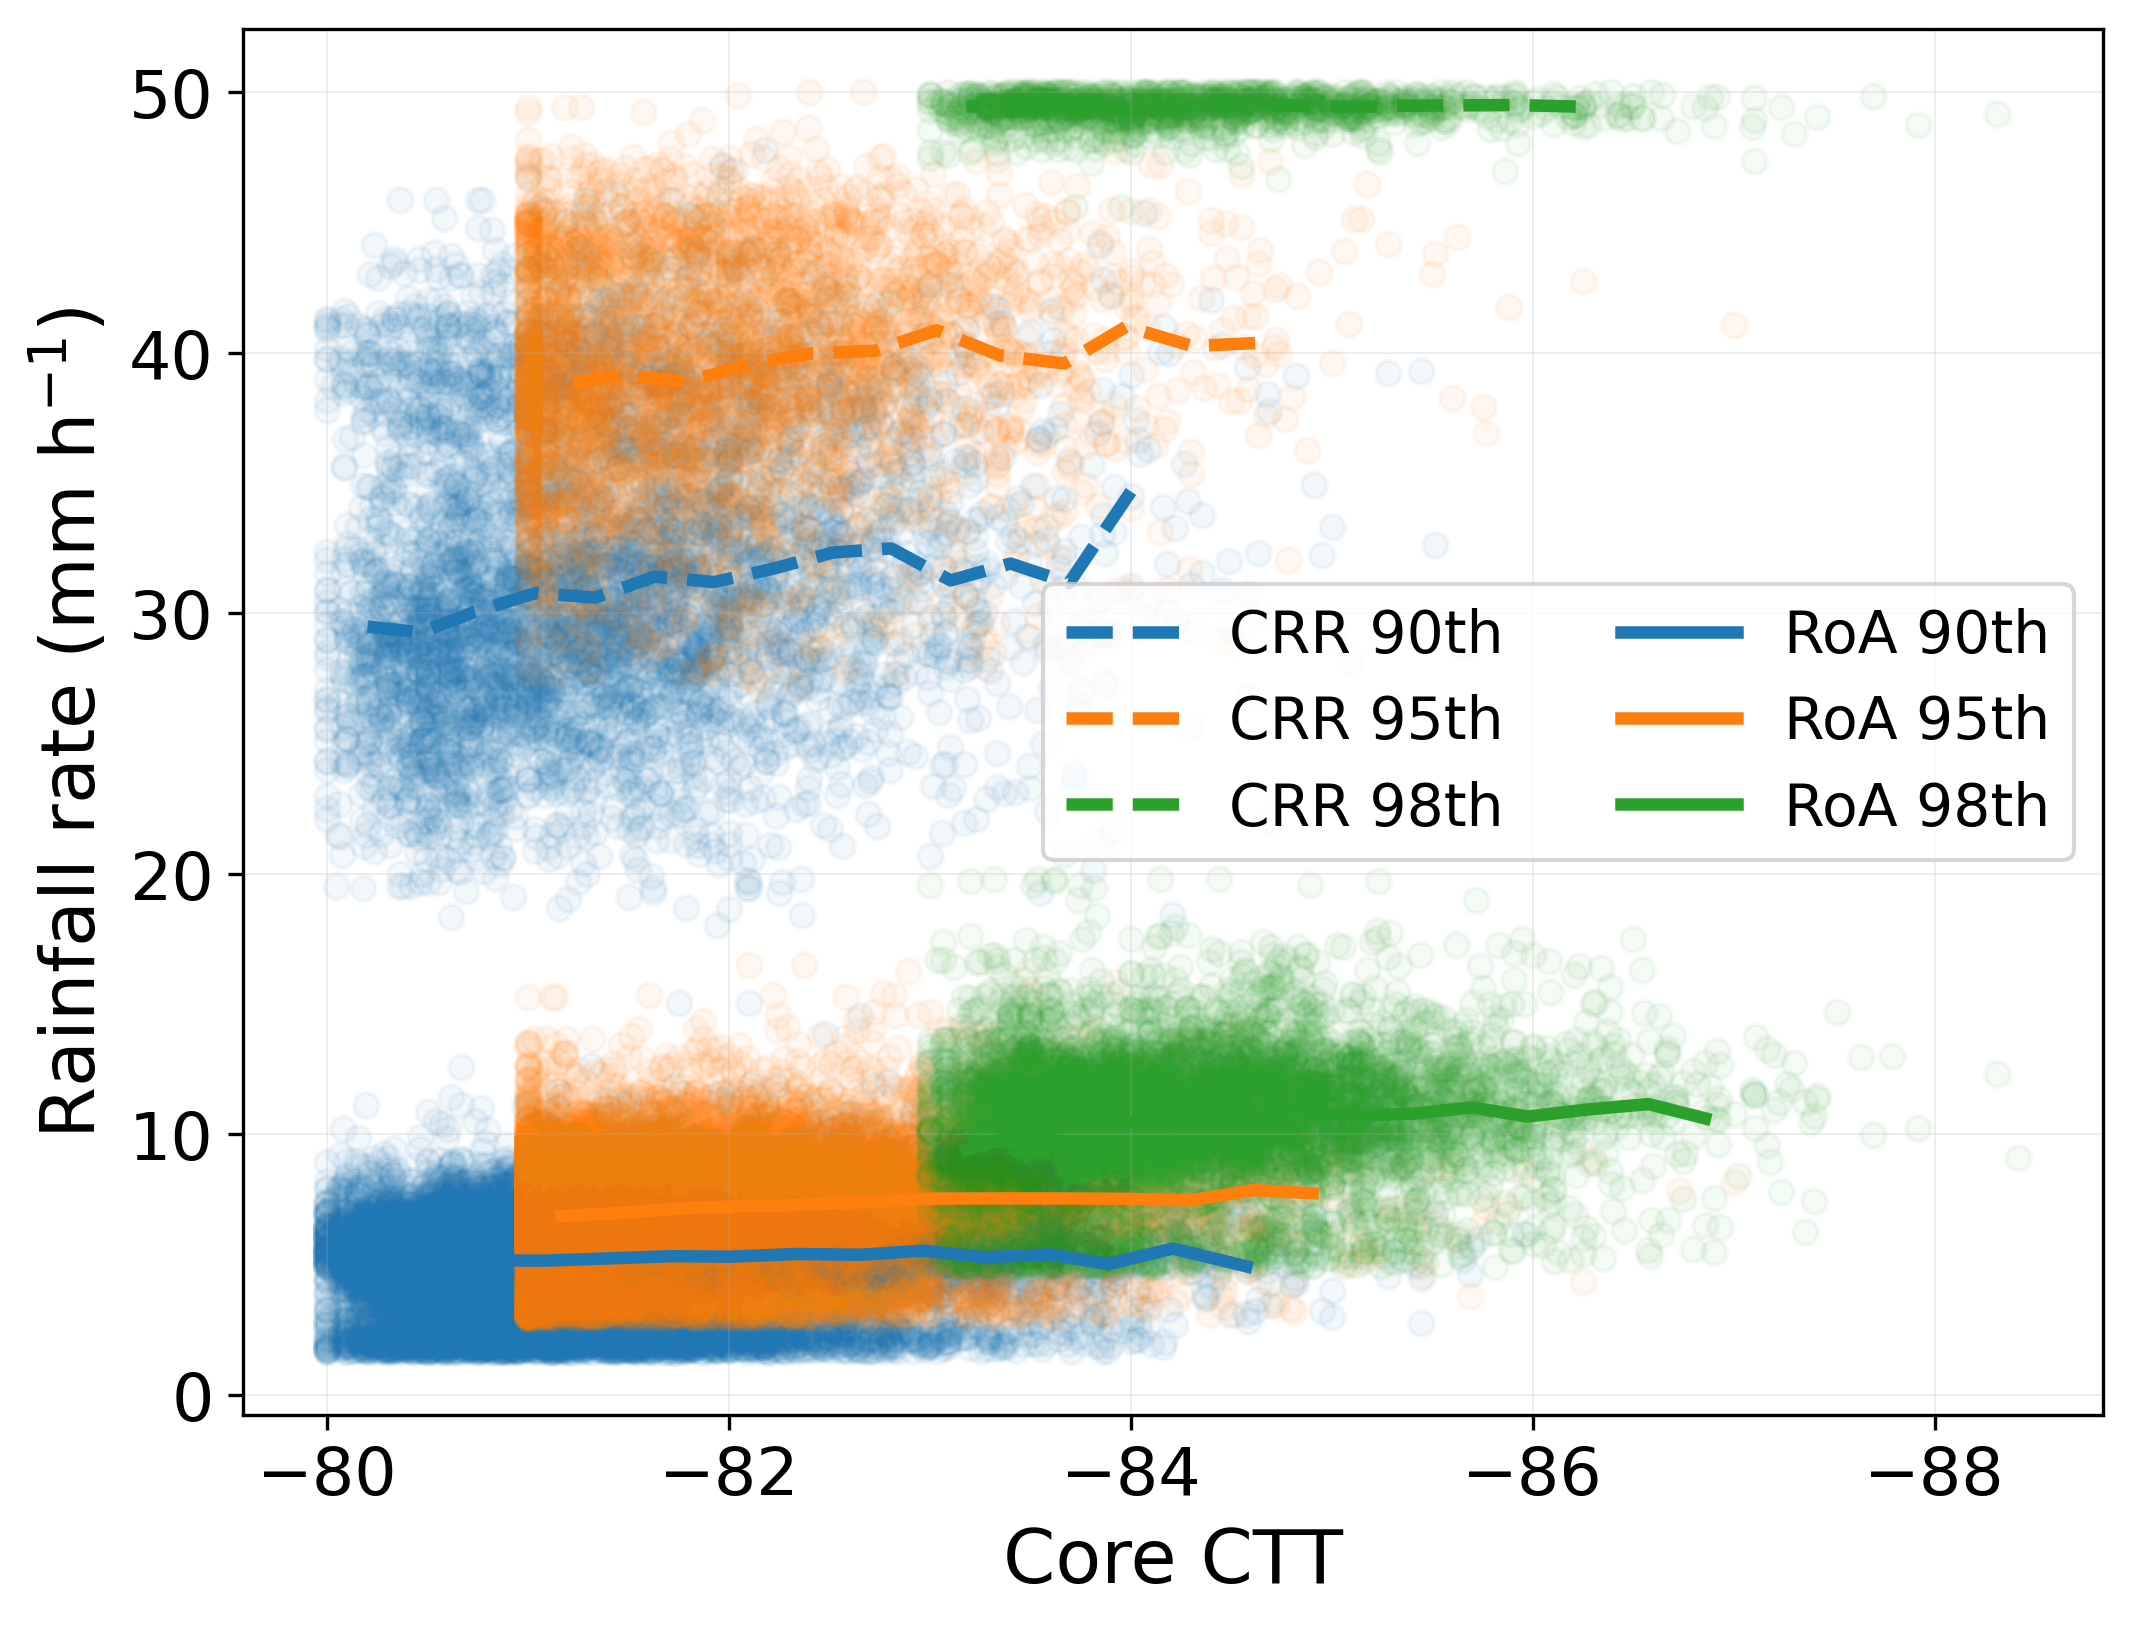

In [13]:
def core_to_rain_values(df_core, df_rain, rain_key):

    core_ctt = []
    rain_val = []

    rain_groups = {t: g for t, g in df_rain.groupby("time")}

    for t, core_group in df_core.groupby("time"):

        rain_group = rain_groups.get(t)

        if rain_group is None or len(core_group) == 0:
            continue

        rain_xy = latlon_to_xy_km(
            rain_group["lat_centroid"].values,
            rain_group["lon_centroid"].values
        )

        tree = cKDTree(rain_xy)

        core_xy = latlon_to_xy_km(
            core_group["lat_centroid"].values,
            core_group["lon_centroid"].values
        )

        dist, idx = tree.query(core_xy, k=1)

        # convert |CTT| → CTT
        core_ctt.extend(-core_group["mean_core"].values)

        rain_val.extend(rain_group[rain_key].values[idx])

    return np.array(core_ctt), np.array(rain_val)


def compute_binned_median(x, y):

    bins = np.linspace(
        x.min(),
        x.max(),
        20
    )

    inds = np.digitize(x, bins)

    centres = []
    medians = []

    for i in range(1, len(bins)):

        mask = inds == i

        if np.sum(mask) < 20:
            continue

        centres.append(np.median(x[mask]))
        medians.append(np.median(y[mask]))

    return np.array(centres), np.array(medians)


# containers
core_wp_crr = {}
rain_crr = {}

core_wp_roa = {}
rain_roa = {}


# --- Core → CRR ---
for cthr, rthr in zip(core_thresholds, crr_thresholds):

    core_wp_crr[rthr], rain_crr[rthr] = core_to_rain_values(
        cores[cthr],
        crrs[rthr],
        "mean_crr"
    )


# --- Core → RoA ---
for cthr, rthr in zip(core_thresholds, roa_thresholds):

    core_wp_roa[rthr], rain_roa[rthr] = core_to_rain_values(
        cores[cthr],
        roas[rthr],
        "mean_roa"
    )


# --- Plot ---
plt.figure(figsize=(8,6), dpi=300)

legend_elements = []

percentiles = ["90", "95", "98"]


# CRR curves
for i,(cthr,rthr) in enumerate(zip(core_thresholds,crr_thresholds)):

    color = f"C{i}"

    x = core_wp_crr[rthr]
    y = rain_crr[rthr] * 10

    plt.scatter(x, y, alpha=0.05, color=color)

    centres, median = compute_binned_median(x, y)

    plt.plot(
        centres,
        median,
        color=color,
        linestyle="--",
        linewidth=3
    )



# RoA curves
for i,(cthr,rthr) in enumerate(zip(core_thresholds,roa_thresholds)):

    color = f"C{i}"

    x = core_wp_roa[rthr]
    y = rain_roa[rthr]

    plt.scatter(x, y, alpha=0.05, color=color)

    centres, median = compute_binned_median(x, y)

    plt.plot(
        centres,
        median,
        color=color,
        linestyle="-",
        linewidth=3
    )


plt.xlabel("Core CTT", fontsize=18)
plt.ylabel("Rainfall rate (mm h$^{-1}$)", fontsize=18)

legend_elements = [
    Line2D([0],[0], color="C0", linestyle="--", lw=3, label="CRR 90th"),
    Line2D([0],[0], color="C1", linestyle="--", lw=3, label="CRR 95th"),
    Line2D([0],[0], color="C2", linestyle="--", lw=3, label="CRR 98th"),

    Line2D([0],[0], color="C0", linestyle="-", lw=3, label="RoA 90th"),
    Line2D([0],[0], color="C1", linestyle="-", lw=3, label="RoA 95th"),
    Line2D([0],[0], color="C2", linestyle="-", lw=3, label="RoA 98th"),
]


plt.legend(
    handles=legend_elements,
    fontsize=14,
    ncol=2
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.grid(True, linewidth=0.1)

plt.gca().invert_xaxis()
plt.show()